# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [5]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

from graph import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

device: cpu
CUDA not available


## Experiment 3: an irregular shape with variable weights (not in the paper)

A 14-vertex shape on a $4 \times 5$ lattice (`X` = vertex, `o` = empty):

```
X o o o X
X X X X X
X X X X X
o X o X o
```

It has 17 edges. Two "horns" hang off the top corners and two "legs" hang off the bottom. Unlike the paper's experiments, the **edge weights vary**: each $w_{xy}$ is drawn from $\mathrm{Uniform}(0.2, 1)$ with a fixed seed. The centrality is $\mu_x = \deg(x)$. We observe the four tips, $B = \{(0,0), (0,4), (3,1), (3,3)\}$, so $|B| = 4$ and $|X \setminus B| = 10$, and we take $T = |X| = 14$.

Check of Assumption 1 (ii): every $w_{xy} \le 1$, so $\sum_y w_{xy} \le \deg(x) = \mu_x$. Since the weights are $< 1$, $p_{xx} > 0$ at every vertex: the walk is lazy, and lazier where the edges are weak.

To try other weights, set `w3` to a number, a dict `{((r1, c1), (r2, c2)): w}`, a function `w(p, q)` of the two coordinates, or an $n \times n$ matrix.

In [6]:
pattern3 = ["X o o o X",
            "X X X X X",
            "X X X X X",
            "o X o X o"]
grid3    = GridGraph.grid_from_pattern(pattern3)
B3_coord = [(0, 0), (0, 4), (3, 1), (3, 3)]
w3       = "random"
w3_low, w3_high, w3_seed = 0.2, 1.0, 0
mu3_kind = "deg"
T3       = len(grid3)
N3       = 10**6
seed3    = 0

|X| = 14, |E| = 17, |B| = 4, T = 14, t_max = 27
p_xx (staying probabilities): [0.024 0.234 0.173 0.295 0.487 0.52  0.335 0.361 0.411 0.483 0.476 0.443
 0.302 0.474]


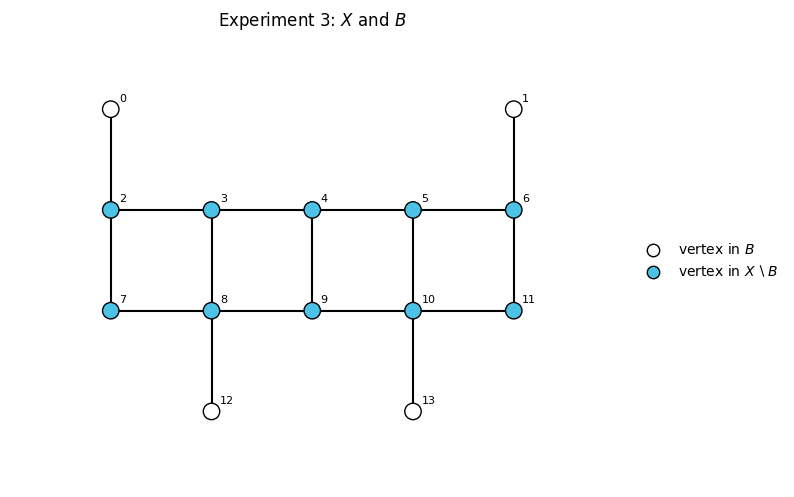

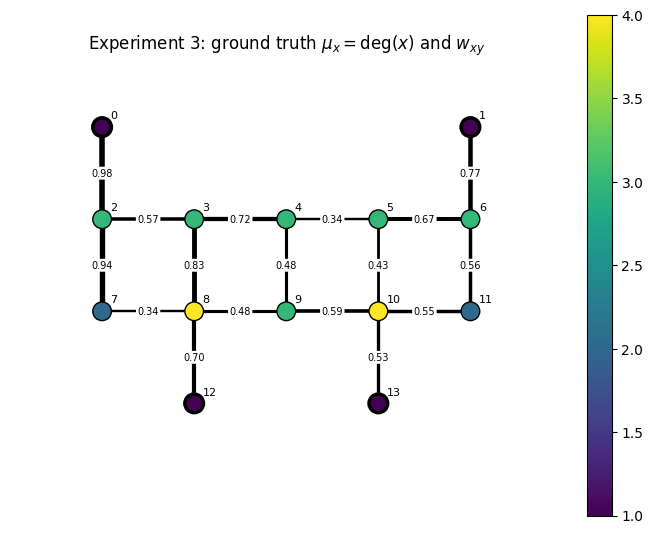

In [7]:
G3 = GridGraph(grid3, B3_coord, w=w3, mu=mu3_kind,
               w_low=w3_low, w_high=w3_high, w_seed=w3_seed)
W3, mu3, B3 = G3.W, G3.mu, G3.B
P3 = G3.transition_matrix()
t_max3 = 2 * T3 - 1
print(f"|X| = {len(mu3)}, |E| = {len(G3.edges)}, |B| = {len(B3)}, T = {T3}, t_max = {t_max3}")
print("p_xx (staying probabilities):", torch.diagonal(P3).numpy().round(3))

plot_graph(G3.grid, B3, title="Experiment 3: $X$ and $B$")
plot_graph(G3.grid, B3, values=mu3, W=W3, title=r"Experiment 3: ground truth $\mu_x = \deg(x)$ and $w_{xy}$")
plt.show()

In [8]:
r3 = exact_first_passage_literal(P3, B3, t_max3)
r3_emp = empirical_first_passage(P3, B3, t_max3, n_walks=N3, seed=seed3)

summarize(P3, B3, r3_emp, r3)

data shape (2T-1, |B|, |B|): (27, 4, 4)
FRNE = 0.263851%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.7369 0.0928 0.4024 0.1148]
 [0.1044 0.7506 0.142  0.3346]
 [0.4006 0.1323 0.6998 0.1663]
 [0.1426 0.3571 0.1972 0.7361]]
probability mass observed by t = 2T-1 (empirical):
 [[0.737  0.0927 0.4021 0.1145]
 [0.1042 0.7507 0.1422 0.3346]
 [0.4017 0.1319 0.7002 0.1669]
 [0.1427 0.358  0.197  0.7362]]


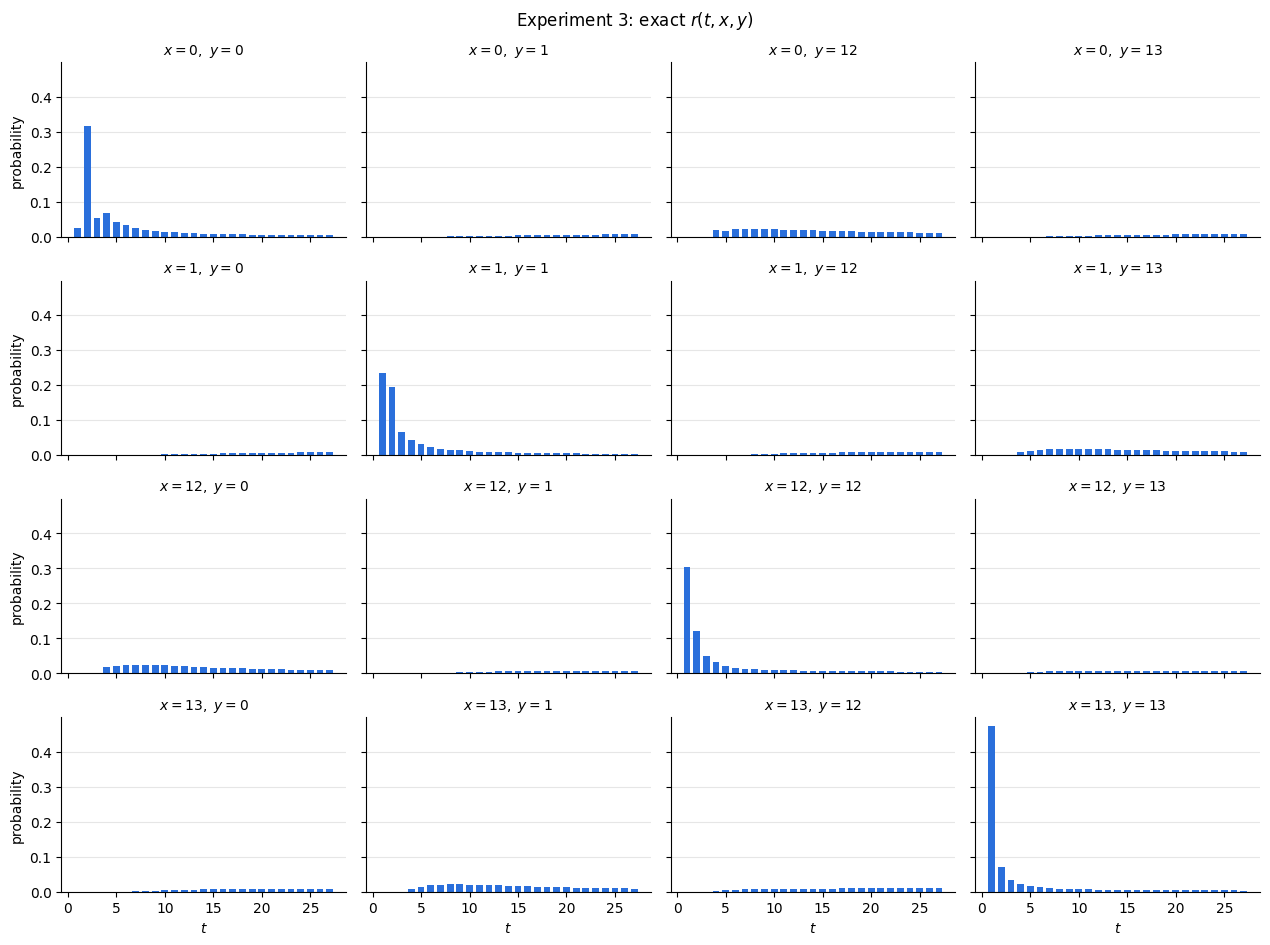

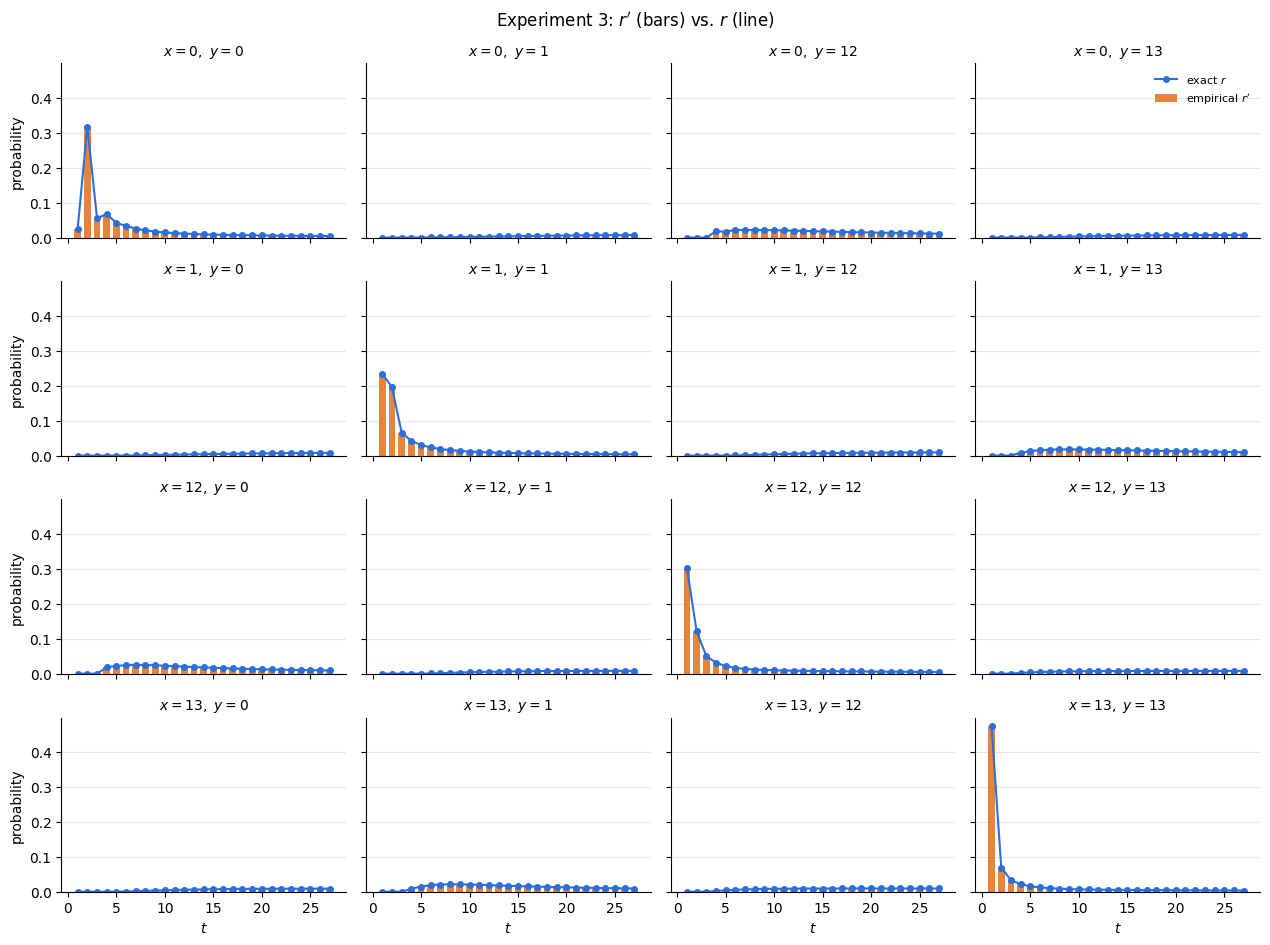

In [9]:
plot_exact_distribution(r3, B3, title="Experiment 3: exact $r(t, x, y)$")
plot_empirical_distribution(r3_emp, B3, r=r3, title="Experiment 3: $r'$ (bars) vs. $r$ (line)")
plt.show()

## Experiment 4: the complete graph $K_5$

`Graph` takes explicit vertex labels and edges, so it supports arbitrary undirected graphs rather than only lattice adjacencies. The same `W`, `mu`, `deg`, `B`, and `transition_matrix()` interface is available. This experiment uses the non-planar complete graph $K_5$, with edge weights $w=0.25$, $\mu_x=1$, and three observed vertices. Each vertex has total incident weight 1, so the walk has no holding probability.

|X| = 5, |E| = 10, |B| = 3, T = 6


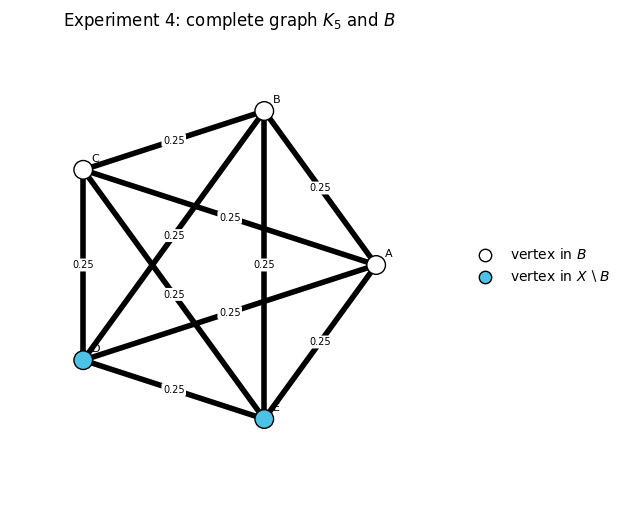

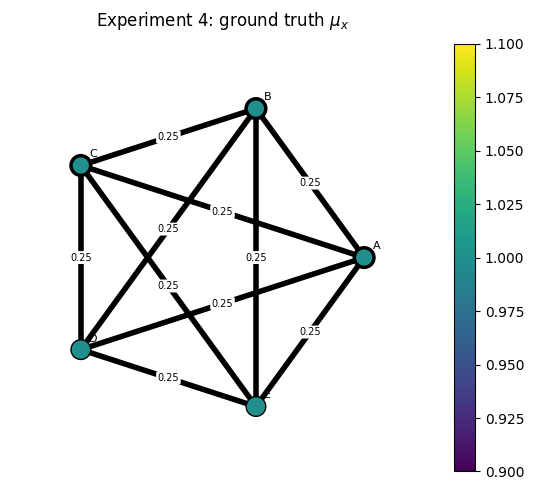

In [10]:
from itertools import combinations

vertices4 = ["A", "B", "C", "D", "E"]
edges4 = list(combinations(vertices4, 2))  # every pair: K_5
B4_labels = ["A", "B", "C"]  # ceil(|X| / 2) observed vertices
G4 = Graph(vertices4, edges4, B4_labels, w=0.25, mu="constant", mu_val=1.0)
W4, mu4, B4 = G4.W, G4.mu, G4.B
P4 = G4.transition_matrix()
T4 = len(vertices4) + 1
t_max4 = 2 * T4 - 1
print(f"|X| = {G4.n}, |E| = {len(G4.edges)}, |B| = {len(B4)}, T = {T4}")

plot_general_graph(G4, title="Experiment 4: complete graph $K_5$ and $B$")
plot_general_graph(G4, values=mu4, title=r"Experiment 4: ground truth $\mu_x$")
plt.show()

data shape (2T-1, |B|, |B|): (11, 3, 3)
FRNE = 0.797382%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.9437 0.9578 0.9578]
 [0.9578 0.9437 0.9578]
 [0.9578 0.9578 0.9437]]
probability mass observed by t = 2T-1 (empirical):
 [[0.945  0.9573 0.9575]
 [0.9587 0.9441 0.9588]
 [0.958  0.9582 0.9421]]


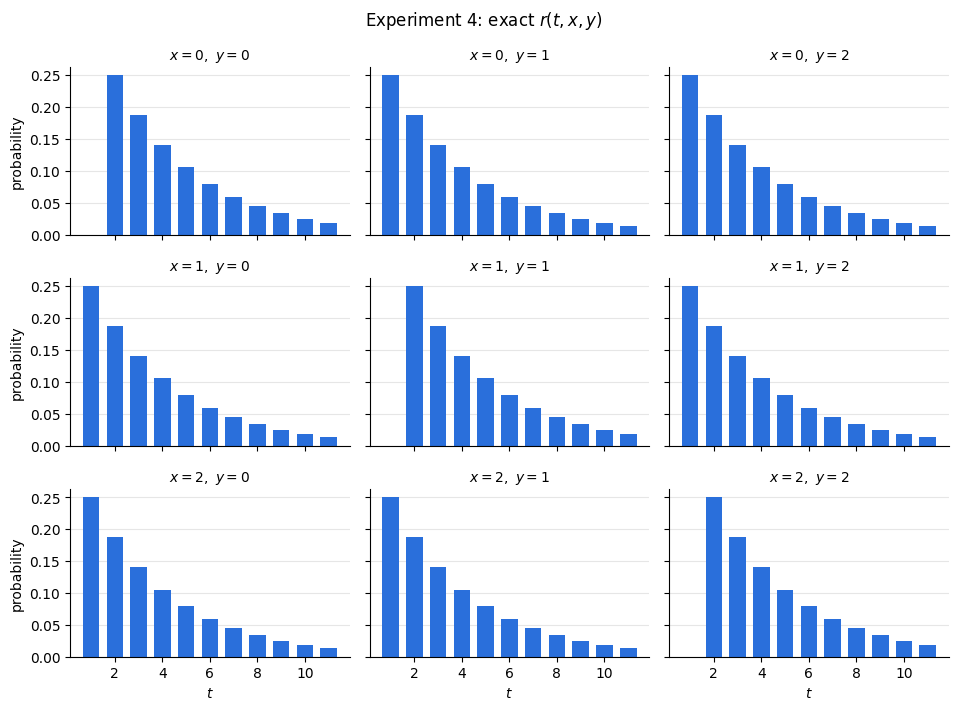

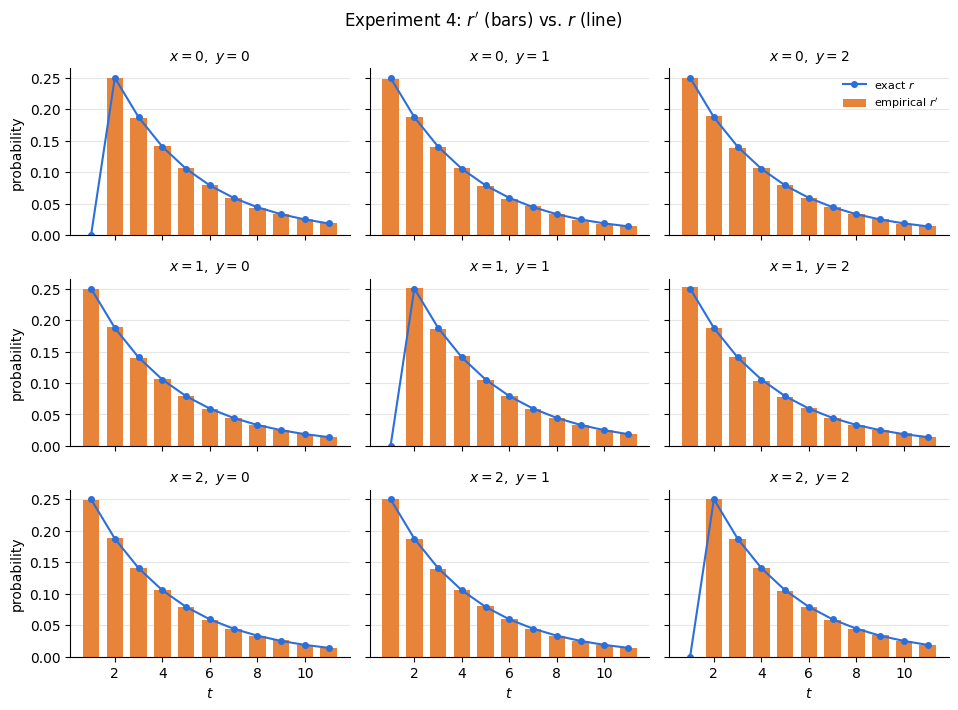

In [11]:
r4 = exact_first_passage_literal(P4, B4, t_max4)
r4_emp = empirical_first_passage(P4, B4, t_max4, n_walks=10**5, seed=0)
summarize(P4, B4, r4_emp, r4)

plot_exact_distribution(r4, B4, title="Experiment 4: exact $r(t, x, y)$")
plot_empirical_distribution(r4_emp, B4, r=r4,
                            title="Experiment 4: $r'$ (bars) vs. $r$ (line)")
plt.show()

### Experiment 4: varying $T$ on $K_5$

Keep $|B|=\lceil |X|/2\rceil=3$ fixed. For every integer $T$ with $|X|<T<200$, calculate FRNE using first-passage data through $t=2T-1$. A single Monte Carlo run at the largest horizon is reused for each prefix, keeping the comparisons efficient and consistent. Increase `N4_T_sweep` to reduce Monte Carlo noise.

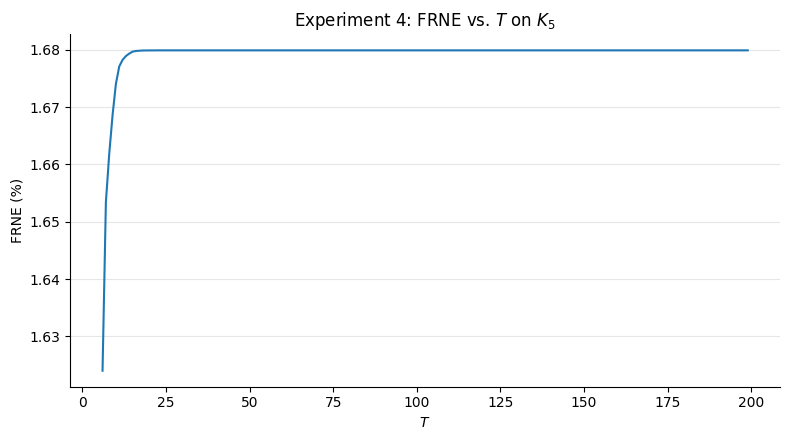

In [12]:
N4_T_sweep = 20_000
seed4_T_sweep = 400
T4_values = list(range(G4.n + 1, 200))
B4_T = torch.tensor([G4.index[v] for v in B4_labels], dtype=torch.long)
t_max4_sweep = 2 * T4_values[-1] - 1
r4_exact_sweep = exact_first_passage_literal(P4, B4_T, t_max4_sweep)
r4_emp_sweep = empirical_first_passage(
    P4, B4_T, t_max4_sweep, n_walks=N4_T_sweep,
    batch=10_000, seed=seed4_T_sweep
)
FRNE4_by_T = [
    frne(r4_exact_sweep[:2 * T - 1], r4_emp_sweep[:2 * T - 1])
    for T in T4_values
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T4_values, FRNE4_by_T, lw=1.5)
ax.set(xlabel="$T$", ylabel="FRNE (%)",
       title="Experiment 4: FRNE vs. $T$ on $K_5$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Experiment 5: the complete bipartite graph $K_{3,3}$

$K_{3,3}$ has two vertex classes of size three and all nine possible cross-edges; it is a standard non-planar graph. We observe the left class, use unit edge weights and $\mu_x=\deg(x)=3$, so the walk has no holding probability. The six-vertex graph uses $T=6$ and first-passage data through $t=2T-1=11$.

K_{3,3}: |X| = 6, |E| = 9, |B| = 3, T = 6, t_max = 11
mu: [3.0, 3.0, 3.0, 3.0, 3.0, 3.0]
p_xx: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


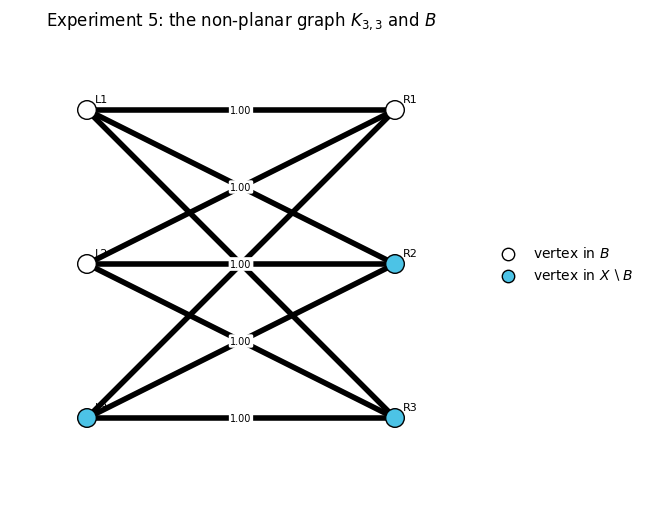

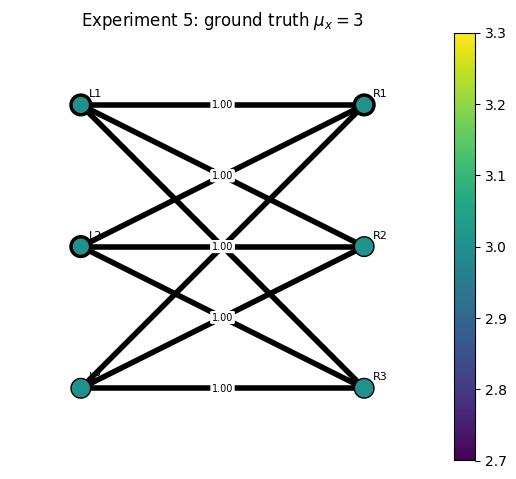

In [13]:
from itertools import product

left3 = ["L1", "L2", "L3"]
right3 = ["R1", "R2", "R3"]
vertices5 = left3 + right3
edges5 = list(product(left3, right3))
B5_labels = ["L1", "L2", "R1"]
positions5 = {
    "L1": (-1, 1), "L2": (-1, 0), "L3": (-1, -1),
    "R1": (1, 1), "R2": (1, 0), "R3": (1, -1),
}
G5 = Graph(vertices5, edges5, B5_labels, w=1.0, mu="deg")
W5, mu5, B5 = G5.W, G5.mu, G5.B
P5 = G5.transition_matrix()
T5 = G5.n
t_max5 = 2 * T5 - 1
print(f"K_{{3,3}}: |X| = {G5.n}, |E| = {len(G5.edges)}, "
      f"|B| = {len(B5)}, T = {T5}, t_max = {t_max5}")
print("mu:", mu5.tolist())
print("p_xx:", torch.diagonal(P5).tolist())

plot_general_graph(G5, title="Experiment 5: the non-planar graph $K_{3,3}$ and $B$",
                  positions=positions5)
plot_general_graph(G5, values=mu5, title=r"Experiment 5: ground truth $\mu_x=3$",
                  positions=positions5)
plt.show()

data shape (2T-1, |B|, |B|): (11, 3, 3)
FRNE = 0.549141%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.8683 0.8683 0.9122]
 [0.8683 0.8683 0.9122]
 [0.9122 0.9122 0.8683]]
probability mass observed by t = 2T-1 (empirical):
 [[0.8681 0.8678 0.9134]
 [0.869  0.8695 0.913 ]
 [0.9131 0.9117 0.8678]]


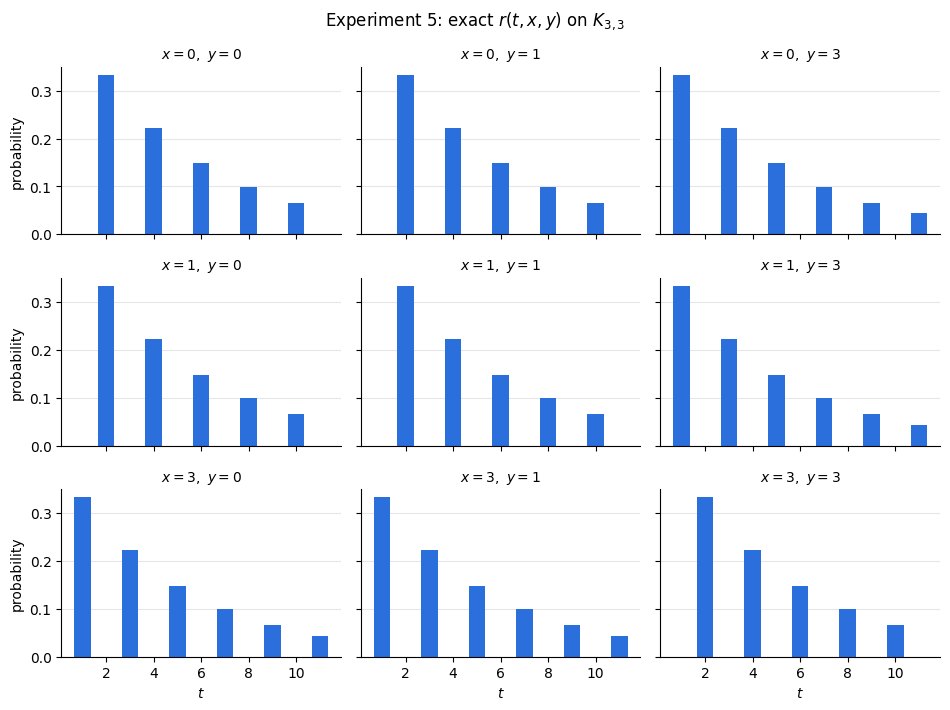

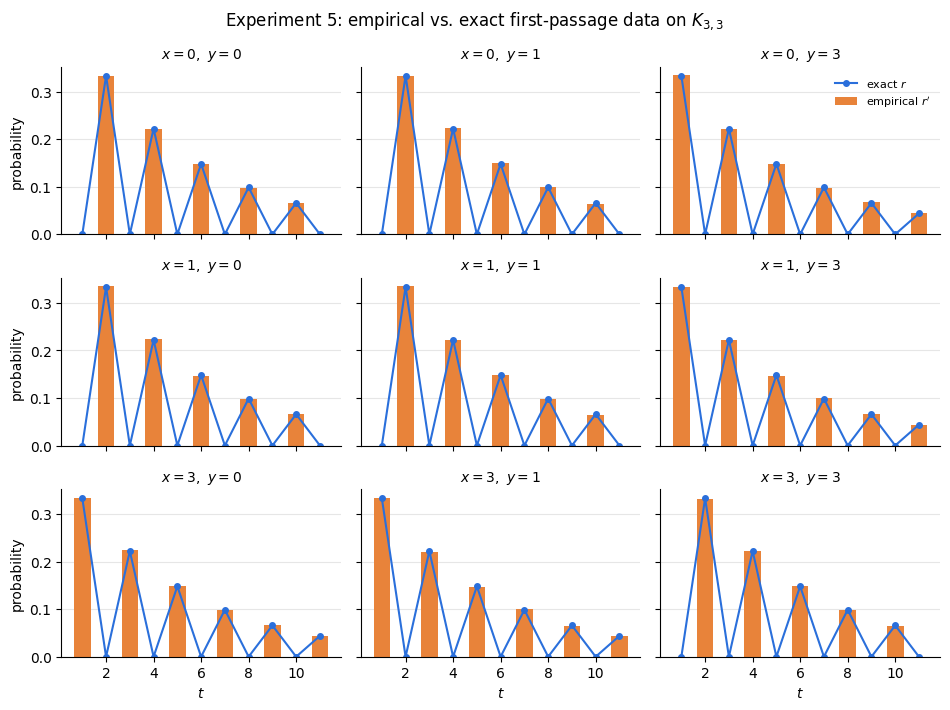

In [14]:
N5 = 10**5
seed5 = 0
r5 = exact_first_passage_literal(P5, B5, t_max5)
r5_emp = empirical_first_passage(P5, B5, t_max5, n_walks=N5, seed=seed5)
summarize(P5, B5, r5_emp, r5)

plot_exact_distribution(r5, B5, title="Experiment 5: exact $r(t, x, y)$ on $K_{3,3}$")
plot_empirical_distribution(r5_emp, B5, r=r5,
                            title="Experiment 5: empirical vs. exact first-passage data on $K_{3,3}$")
plt.show()

### Experiment 5: varying $T$ on $K_{3,3}$

Keep the left partition as $B$, so $|B|=3=\lceil |X|/2\rceil$. For every integer $T$ with $|X|<T<200$, calculate FRNE through $t=2T-1$. One Monte Carlo run at the maximum horizon supplies each prefix. Increase `N5_T_sweep` to reduce Monte Carlo noise.

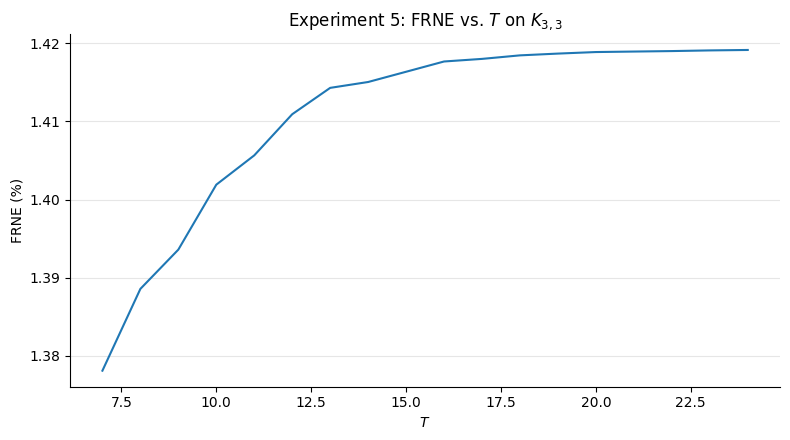

In [15]:
N5_T_sweep = 20_000
seed5_T_sweep = 500
T5_values = list(range(G5.n + 1, 25))
t_max5_sweep = 2 * T5_values[-1] - 1
r5_exact_sweep = exact_first_passage_literal(P5, B5, t_max5_sweep)
r5_emp_sweep = empirical_first_passage(
    P5, B5, t_max5_sweep, n_walks=N5_T_sweep,
    batch=10_000, seed=seed5_T_sweep
)
FRNE5_by_T = [
    frne(r5_exact_sweep[:2 * T - 1], r5_emp_sweep[:2 * T - 1])
    for T in T5_values
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T5_values, FRNE5_by_T, lw=1.5)
ax.set(xlabel="$T$", ylabel="FRNE (%)",
       title="Experiment 5: FRNE vs. $T$ on $K_{3,3}$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Experiment 6: a tree with 15 vertices

Use a connected, branching tree with 15 vertices and 14 edges. The central vertex has degree 5, and several other vertices have degree greater than 2. Each edge has weight $0.15$ and each vertex has weight $\mu_x=1$, so even the highest total incident edge weight is $0.75$ and the holding probabilities are nonnegative. The nine leaves form the observation set $B$.

|X| = 15, |E| = 14, |B| = 4, T = 20, t_max = 39
degree: [5.0, 4.0, 3.0, 3.0, 2.0, 2.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
p_xx: [0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85]


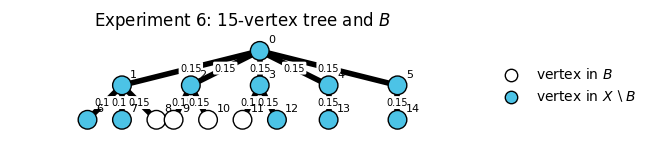

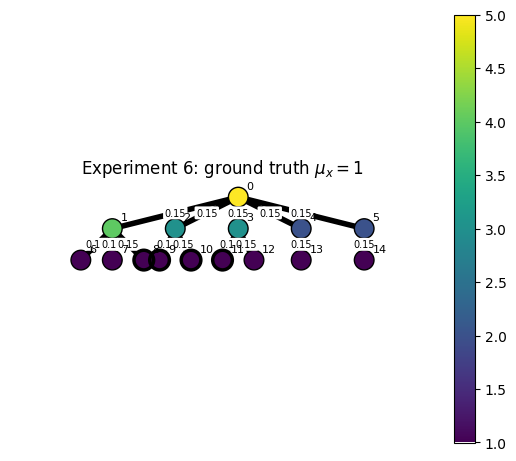

In [16]:
vertices6 = list(range(15))
edges6 = [
    (0, 1), (0, 2), (0, 3), (0, 4), (0, 5),
    (1, 6), (1, 7), (1, 8),
    (2, 9), (2, 10), (3, 11), (3, 12), (4, 13), (5, 14),
]
B6_labels = list(range(8, 12))  # the nine leaves
positions6 = {
    0: (0, 3), 1: (-4, 2), 2: (-2, 2), 3: (0, 2), 4: (2, 2), 5: (4, 2),
    6: (-5, 1), 7: (-4, 1), 8: (-3, 1),
    9: (-2.5, 1), 10: (-1.5, 1), 11: (-0.5, 1), 12: (0.5, 1),
    13: (2, 1), 14: (4, 1),
}
G6 = Graph(vertices6, edges6, B6_labels, w=0.15, mu="deg", mu_val=1.0)
W6, mu6, B6 = G6.W, G6.mu, G6.B
P6 = G6.transition_matrix()
T6 = 20
t_max6 = 2 * T6 - 1
print(f"|X| = {G6.n}, |E| = {len(G6.edges)}, |B| = {len(B6)}, "
      f"T = {T6}, t_max = {t_max6}")
print("degree:", G6.deg.tolist())
print("p_xx:", torch.diagonal(P6).tolist())

plot_general_graph(G6, title="Experiment 6: 15-vertex tree and $B$",
                  positions=positions6)
plot_general_graph(G6, values=mu6, title=r"Experiment 6: ground truth $\mu_x=1$",
                  positions=positions6)
plt.show()

data shape (2T-1, |B|, |B|): (39, 4, 4)
FRNE = 0.514532%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.9183 0.0358 0.0358 0.0358]
 [0.0373 0.9271 0.4845 0.0455]
 [0.0373 0.4845 0.9271 0.0455]
 [0.0373 0.0455 0.0455 0.9271]]
probability mass observed by t = 2T-1 (empirical):
 [[0.9168 0.0354 0.0382 0.036 ]
 [0.0358 0.9258 0.4806 0.0474]
 [0.0385 0.4832 0.925  0.0469]
 [0.0381 0.043  0.0469 0.9282]]


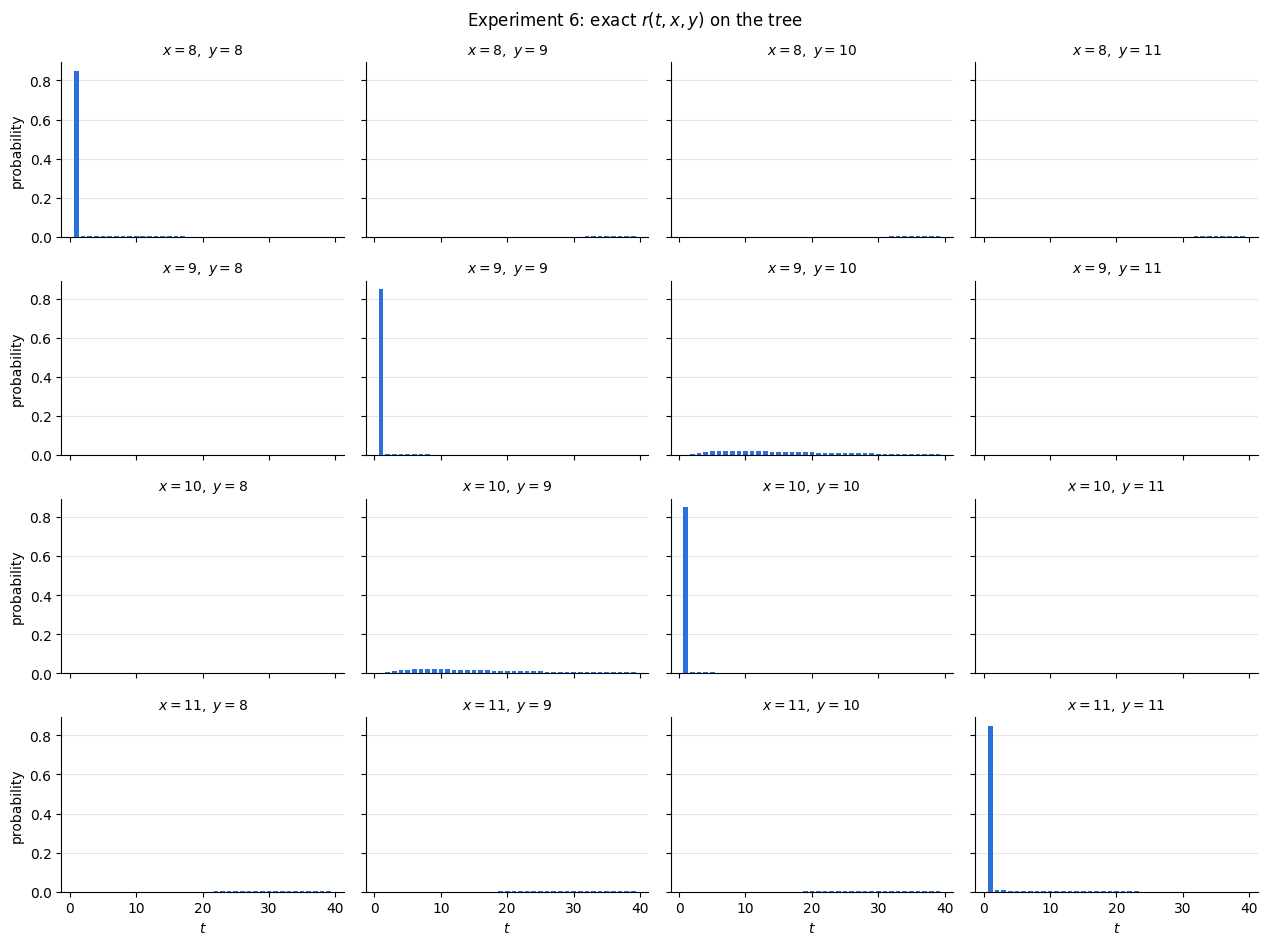

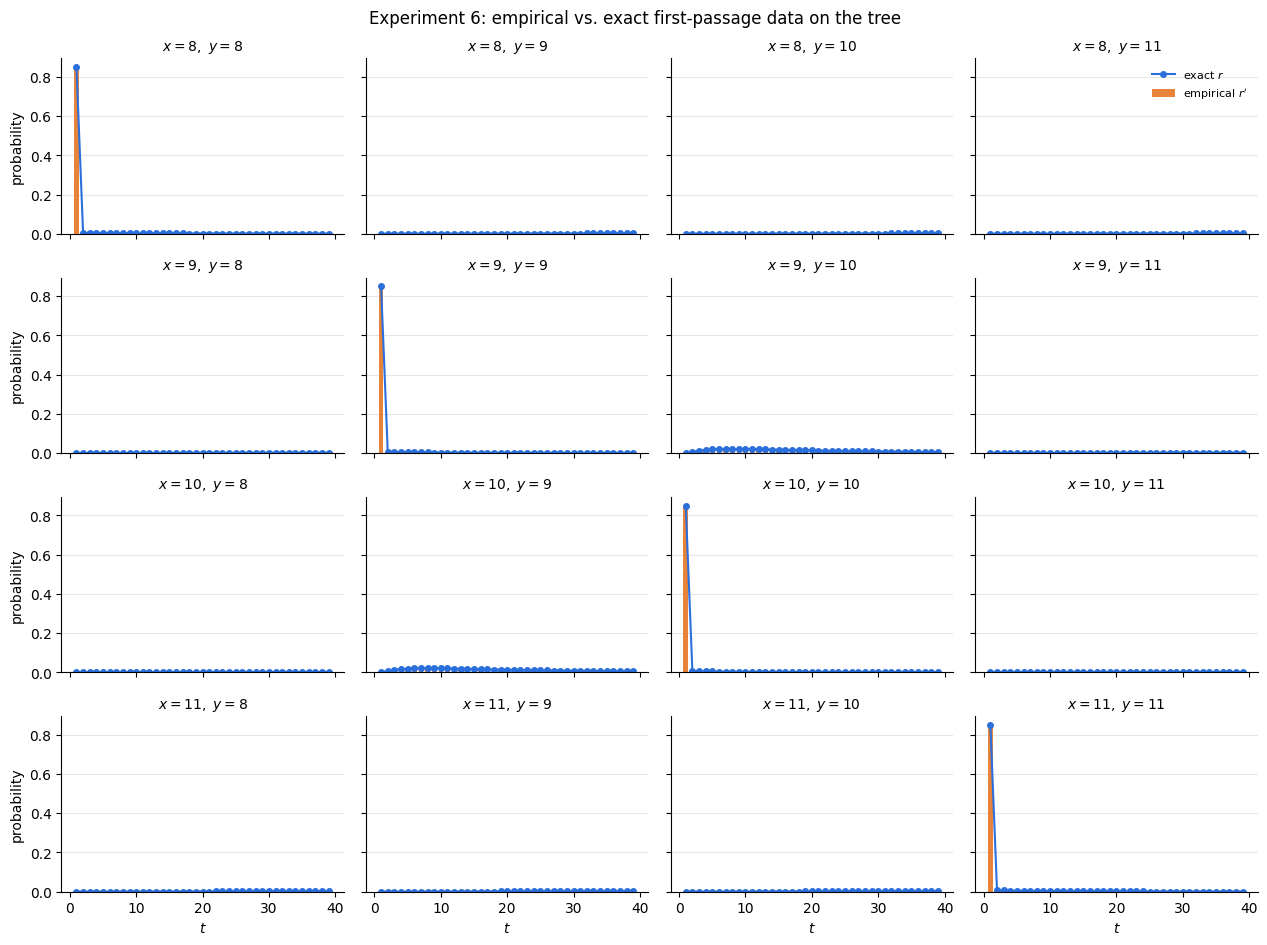

In [17]:
N6 = 20_000
seed6 = 0
r6 = exact_first_passage_literal(P6, B6, t_max6)
r6_emp = empirical_first_passage(P6, B6, t_max6, n_walks=N6, seed=seed6)
summarize(P6, B6, r6_emp, r6)

plot_exact_distribution(r6, B6, title="Experiment 6: exact $r(t, x, y)$ on the tree")
plot_empirical_distribution(r6_emp, B6, r=r6,
                            title="Experiment 6: empirical vs. exact first-passage data on the tree")
plt.show()

## Experiment 7: the dumbbell graph $D_7$

The dumbbell graph $D_7$ has two copies of $K_7$ joined by a single bridge edge, for 14 vertices total. This experiment uses unit edge weights and sets $\mu_x=\deg(x)$, so there is no holding probability. The left clique is the initial observation set $B$ (so $|B|=7$). The following cells run the exact and empirical first-passage simulations, evaluate every nonempty proper subset $B$ (16,382 subsets), and sweep $T$ for the fixed left-clique observation set.

|X| = 14, |E| = 43, |B| = 6, T = 20, t_max = 39
degree: [7.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 7.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0]
p_xx: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


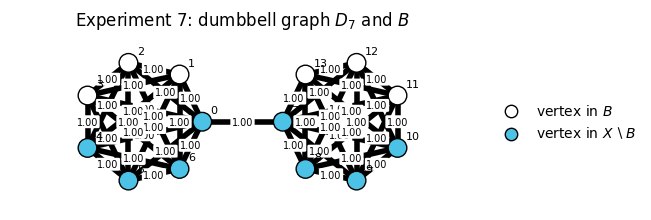

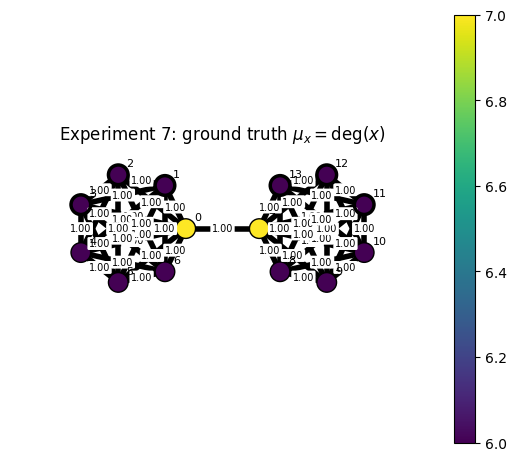

data shape (2T-1, |B|, |B|): (39, 6, 6)
FRNE = 2.615571%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.9234 0.9345 0.9345 0.4144 0.4144 0.4144]
 [0.9345 0.9234 0.9345 0.4144 0.4144 0.4144]
 [0.9345 0.9345 0.9234 0.4144 0.4144 0.4144]
 [0.4144 0.4144 0.4144 0.9234 0.9345 0.9345]
 [0.4144 0.4144 0.4144 0.9345 0.9234 0.9345]
 [0.4144 0.4144 0.4144 0.9345 0.9345 0.9234]]
probability mass observed by t = 2T-1 (empirical):
 [[0.9246 0.9331 0.9348 0.4118 0.4194 0.4174]
 [0.9364 0.9264 0.9373 0.4206 0.4136 0.4156]
 [0.9333 0.935  0.9253 0.415  0.4179 0.415 ]
 [0.421  0.4154 0.4153 0.9255 0.9359 0.9356]
 [0.4152 0.418  0.4173 0.9353 0.9247 0.9352]
 [0.4128 0.4152 0.4172 0.9355 0.936  0.9222]]


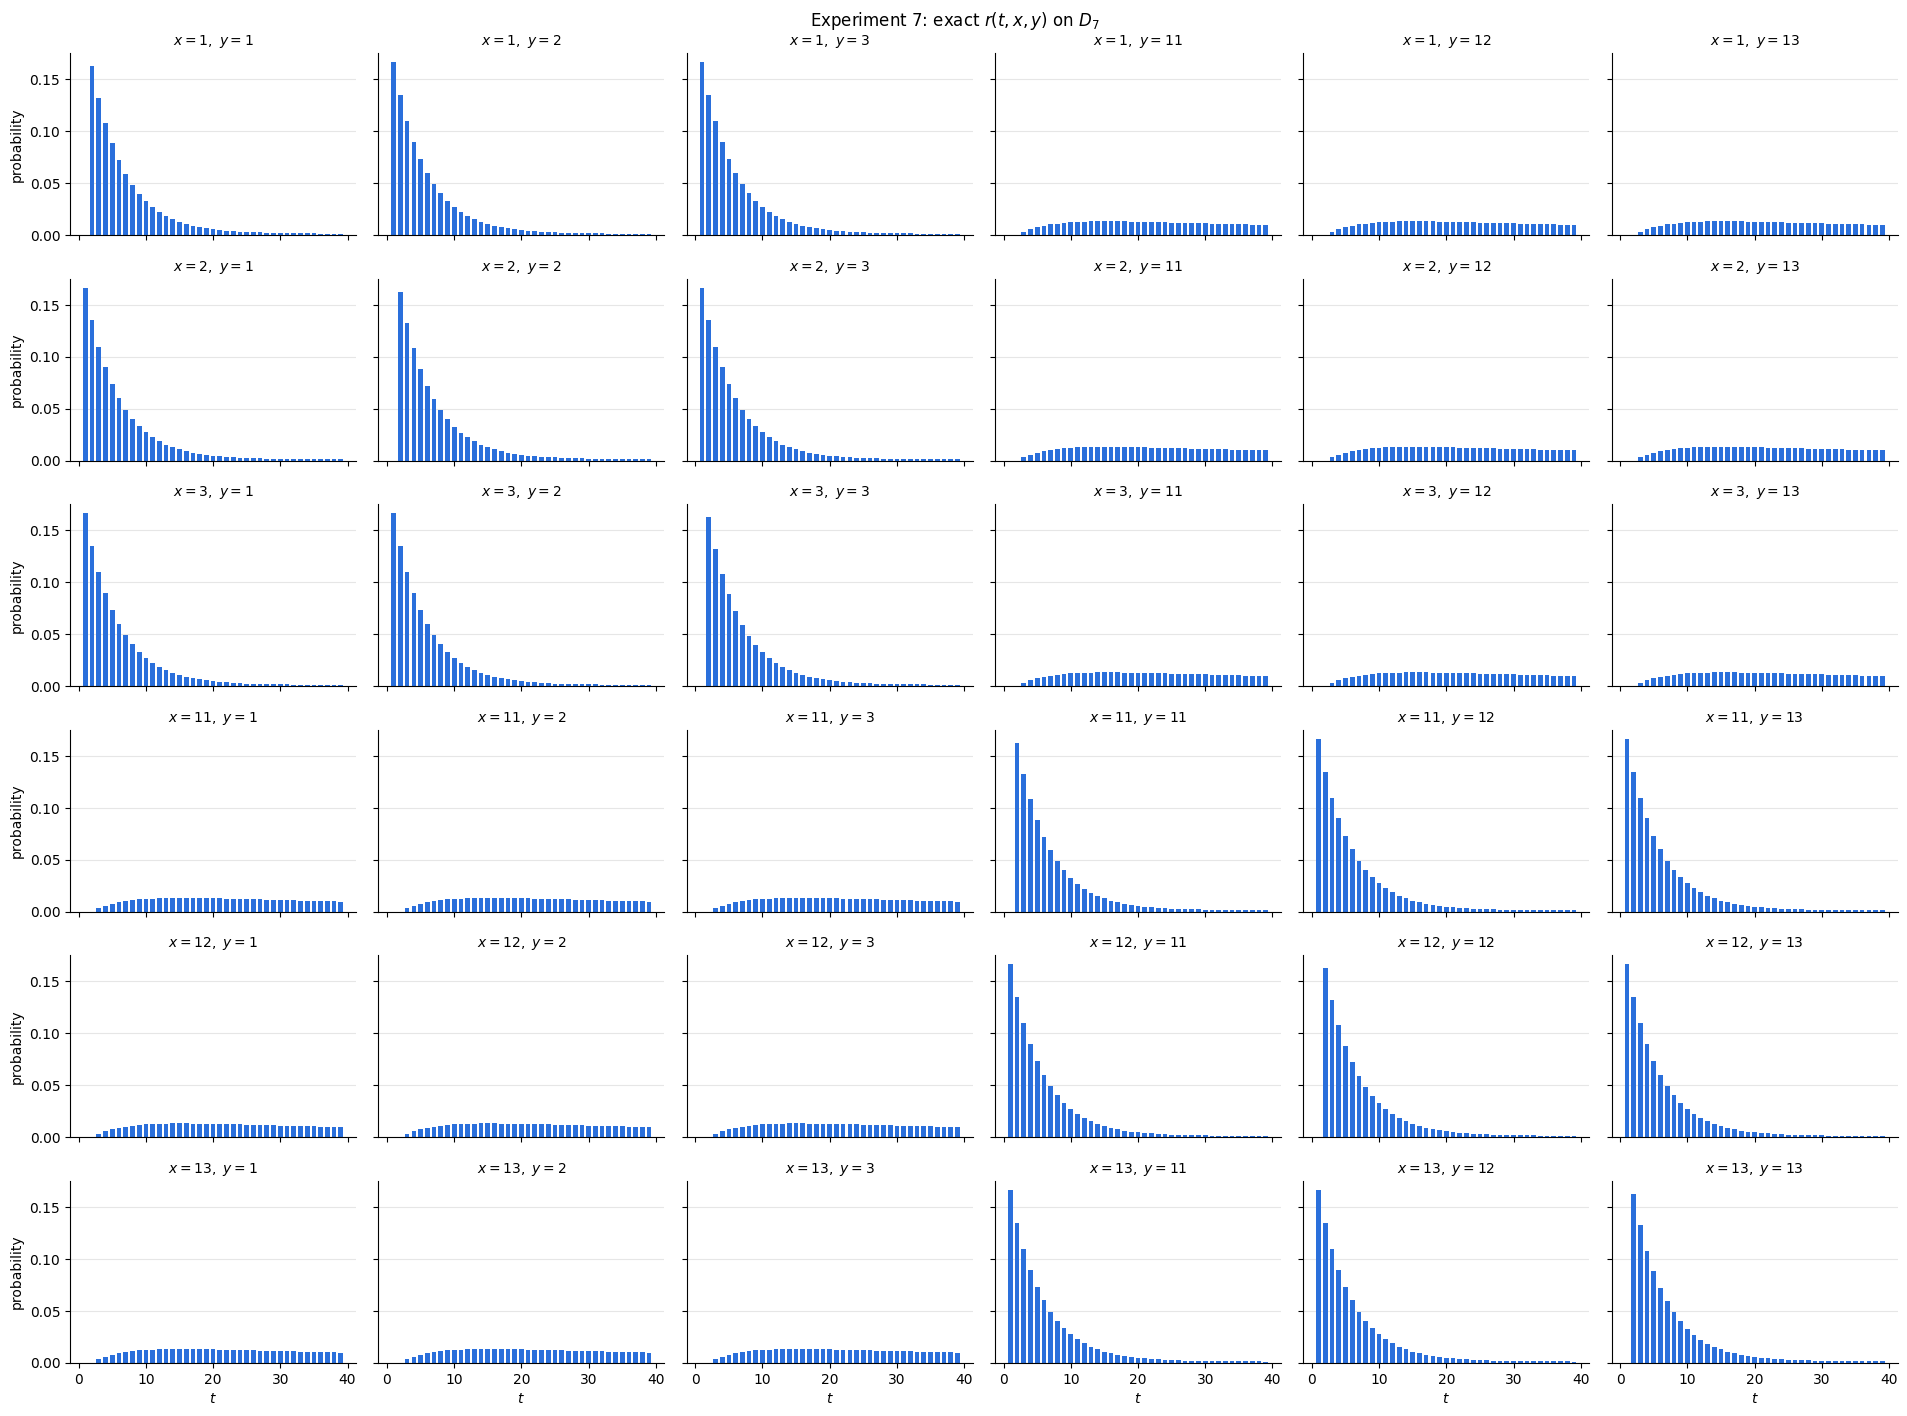

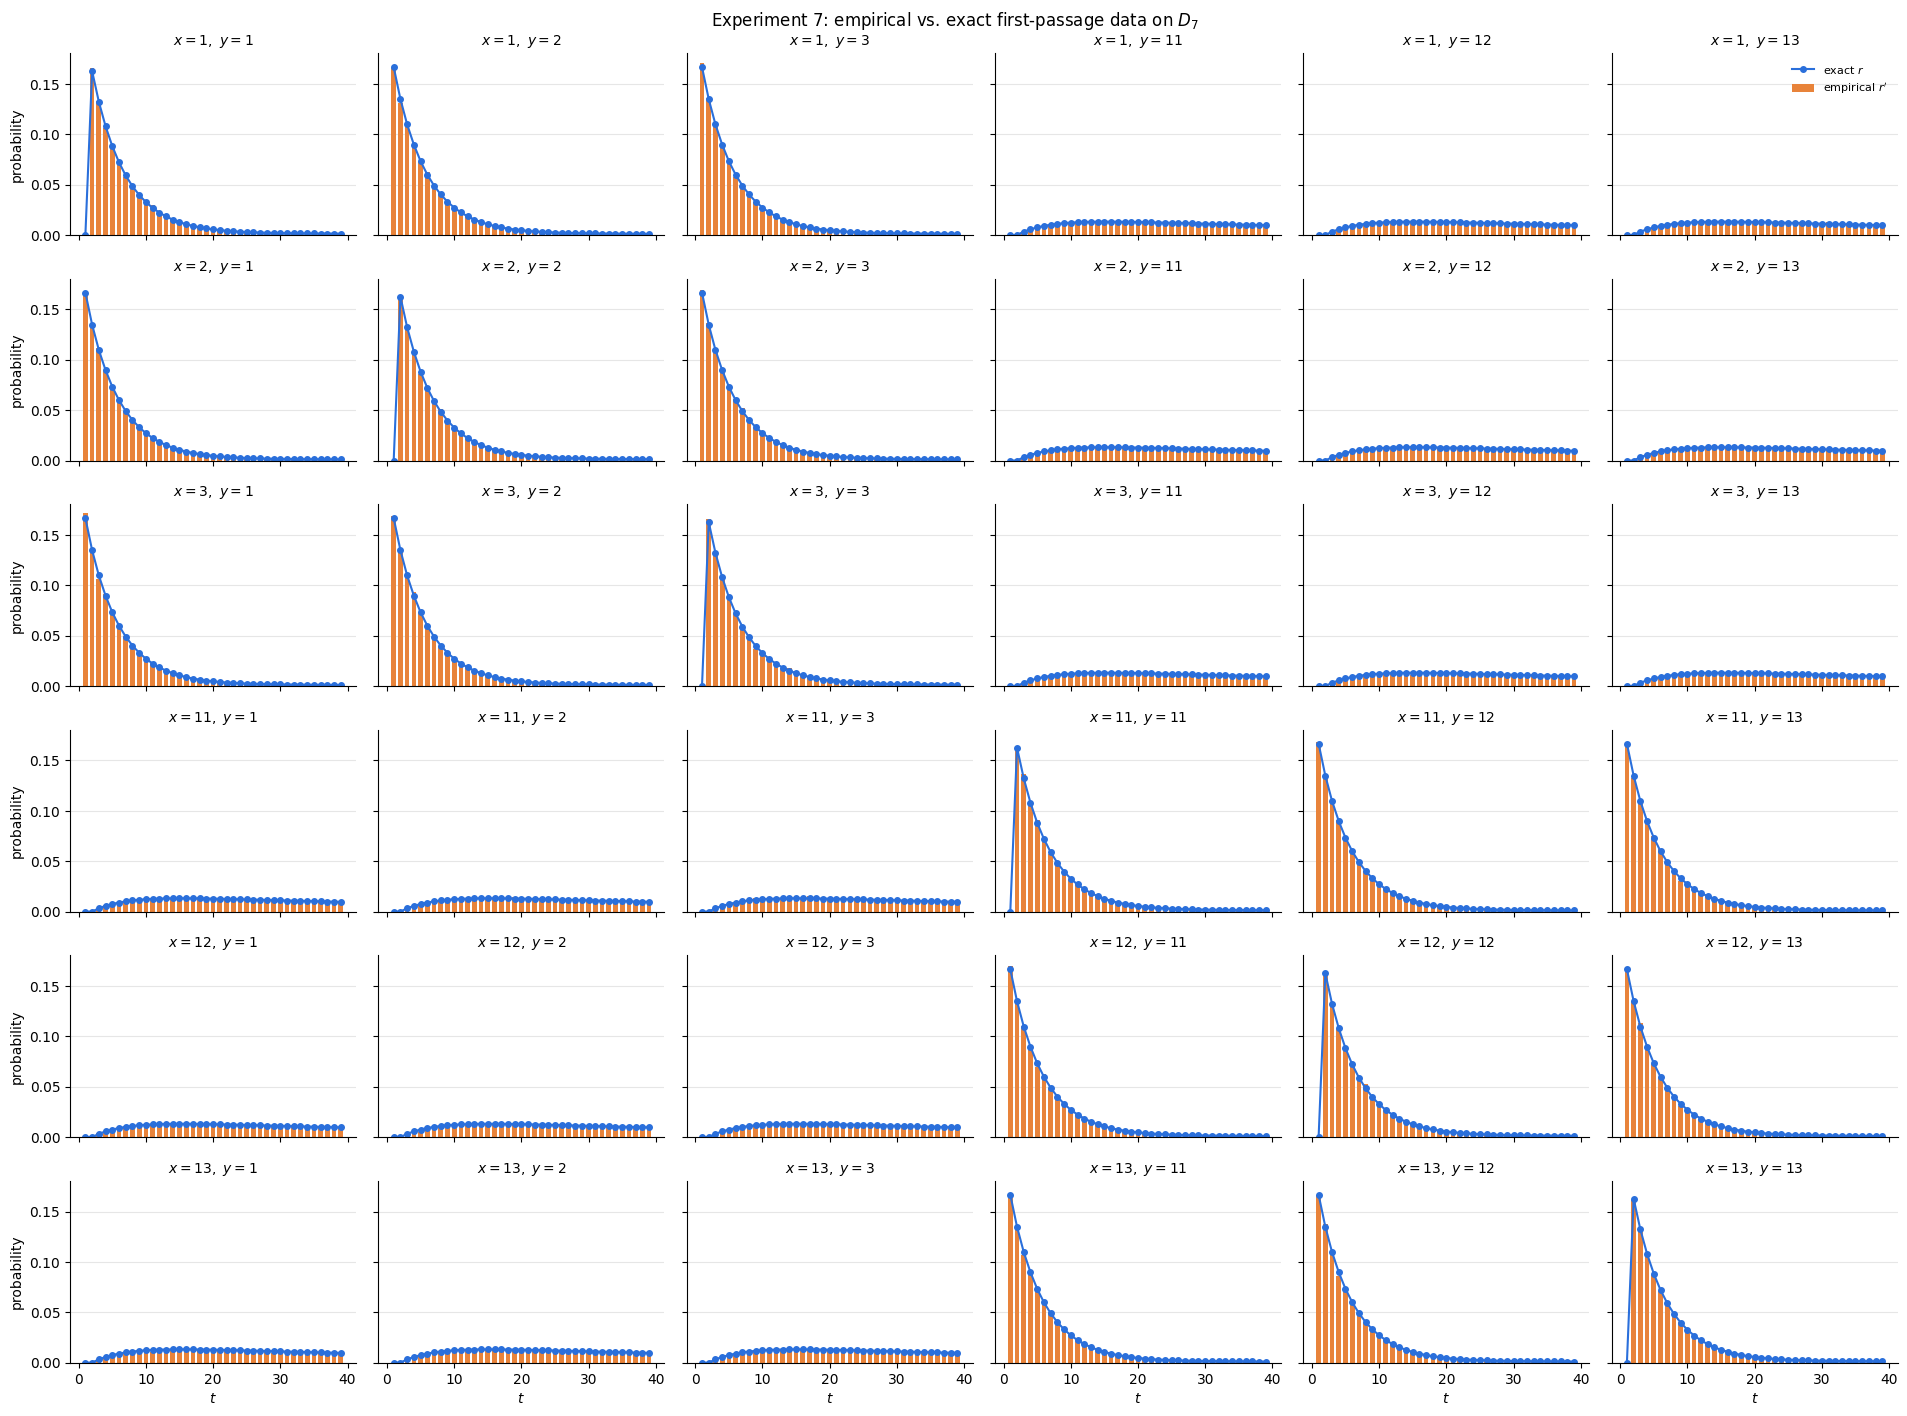

In [18]:
from itertools import combinations

vertices7 = list(range(14))
edges7 = (list(combinations(range(7), 2))
          + list(combinations(range(7, 14), 2))
          + [(0, 7)])
B7_labels = [1,2,3,11,12,13]
positions7 = {
    **{i: (-2 + 1.2 * np.cos(2 * np.pi * i / 7),
           1.2 * np.sin(2 * np.pi * i / 7)) for i in range(7)},
    **{7 + i: (2 + 1.2 * np.cos(np.pi + 2 * np.pi * i / 7),
               1.2 * np.sin(np.pi + 2 * np.pi * i / 7)) for i in range(7)},
}

G7 = Graph(vertices7, edges7, B7_labels, w=1.0, mu="deg", mu_val=1.0)
W7, mu7, B7 = G7.W, G7.mu, G7.B
P7 = G7.transition_matrix()
T7 = 20
t_max7 = 2 * T7 - 1
print(f"|X| = {G7.n}, |E| = {len(G7.edges)}, |B| = {len(B7)}, "
      f"T = {T7}, t_max = {t_max7}")
print("degree:", G7.deg.tolist())
print("p_xx:", torch.diagonal(P7).tolist())

plot_general_graph(G7, title="Experiment 7: dumbbell graph $D_7$ and $B$",
                  positions=positions7)
plot_general_graph(G7, values=mu7, title=r"Experiment 7: ground truth $\mu_x=\deg(x)$",
                  positions=positions7)
plt.show()

N7 = 20_000
seed7 = 700
r7 = exact_first_passage_literal(P7, B7, t_max7)
r7_emp = empirical_first_passage(P7, B7, t_max7, n_walks=N7, seed=seed7)
summarize(P7, B7, r7_emp, r7)

plot_exact_distribution(r7, B7, title="Experiment 7: exact $r(t, x, y)$ on $D_7$")
plot_empirical_distribution(r7_emp, B7, r=r7,
                            title="Experiment 7: empirical vs. exact first-passage data on $D_7$")
plt.show()

### Experiment 7: varying $B$ on $D_7$

For every size $|B|=1,\ldots,13$, sample 10 distinct subsets of vertices and compare empirical with exact first-passage data through $t=2T_7-1$. The sample is reproducible and the box plot shows the FRNE distribution by subset size. Increase `N7_B_sweep` only if additional Monte Carlo accuracy is needed.

In [19]:
N7_B_sweep = 10**4
B7_sweep_sizes = list(range(1, G7.n))
B7_sweep_frne = {nB: [] for nB in B7_sweep_sizes}
B7_sweep_results = []
rng7_B_sweep = np.random.default_rng(seed7)

for nB in B7_sweep_sizes:
    all_subsets = list(combinations(range(G7.n), nB))
    selected = rng7_B_sweep.choice(
        len(all_subsets), size=min(10, len(all_subsets)), replace=False
    )
    for subset_index in selected:
        vertex_indices = all_subsets[int(subset_index)]
        B_sweep7 = torch.tensor(vertex_indices, dtype=torch.long)
        r_exact7_sweep = exact_first_passage_literal(P7, B_sweep7, t_max7)
        subset_seed7 = seed7 + sum(1 << i for i in vertex_indices)
        r_emp7_sweep = empirical_first_passage(
            P7, B_sweep7, t_max7, n_walks=N7_B_sweep,
            batch=min(10**4, N7_B_sweep), seed=subset_seed7
        )
        subset_frne7 = frne(r_exact7_sweep, r_emp7_sweep)
        B7_sweep_frne[nB].append(subset_frne7)
        B7_sweep_results.append({
            "size": nB,
            "indices": vertex_indices,
            "vertices": tuple(vertices7[i] for i in vertex_indices),
            "frne": subset_frne7,
        })

B7_best_by_size = {
    nB: min((result for result in B7_sweep_results if result["size"] == nB),
            key=lambda result: result["frne"])
    for nB in B7_sweep_sizes
}
B7_best_overall = min(B7_sweep_results, key=lambda result: result["frne"])

print(f"Evaluated {len(B7_sweep_results)} subsets.")
for nB, result in B7_best_by_size.items():
    print(f"|B|={nB}: best FRNE={result['frne']:.6f}%; "
          f"vertices={list(result['vertices'])}; indices={result['indices']}")
print("Overall best subset:", B7_best_overall)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([B7_sweep_frne[nB] for nB in B7_sweep_sizes],
           positions=B7_sweep_sizes, showmeans=True)
ax.set_xticks(B7_sweep_sizes)
ax.set_xlabel(r"Number of observed vertices, $|B|$")
ax.set_ylabel("FRNE (%)")
ax.set_title(r"Experiment 7: FRNE across all subsets of each size on $D_7$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

KeyboardInterrupt: 

### Experiment 7: varying $T$ on $D_7$

Keep the left clique as $B$ and calculate FRNE through $t=2T-1$ for each integer $T$ from 15 through 24. A single Monte Carlo run at the largest horizon is reused for every prefix.

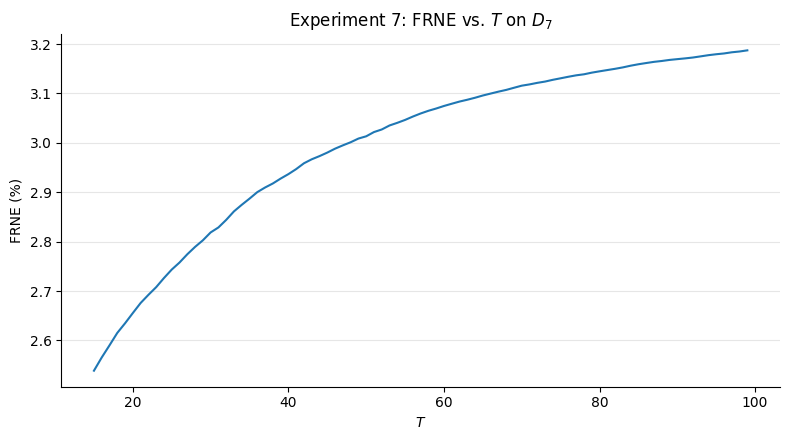

In [21]:
N7_T_sweep = 20_000
seed7_T_sweep = 700
T7_values = list(range(G7.n + 1, 100))
t_max7_sweep = 2 * T7_values[-1] - 1
r7_exact_sweep = exact_first_passage_literal(P7, B7, t_max7_sweep)
r7_emp_sweep = empirical_first_passage(
    P7, B7, t_max7_sweep, n_walks=N7_T_sweep,
    batch=10_000, seed=seed7_T_sweep
)
FRNE7_by_T = [
    frne(r7_exact_sweep[:2 * T - 1], r7_emp_sweep[:2 * T - 1])
    for T in T7_values
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T7_values, FRNE7_by_T, lw=1.5)
ax.set(xlabel="$T$", ylabel="FRNE (%)",
       title="Experiment 7: FRNE vs. $T$ on $D_7$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()